In [ ]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from matplotlib.patches import Ellipse

from ics26_experiments import get_N_TRAIN
from src.adaptive_clustering import adaptive_clustering
from src.problems.anisotropic_quadratic import aniso_quadratic, aniso_quadratic_grad
from src.problems.quadratic import quadratic, quadratic_grad
from src.problems.shifted_gaussians import (
    CENTERS_2D,
    shifted_gaussians,
    shifted_gaussians_grad,
)

# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)

Number of clusters without Hessian: 49
Number of clusters with Hessian: 8


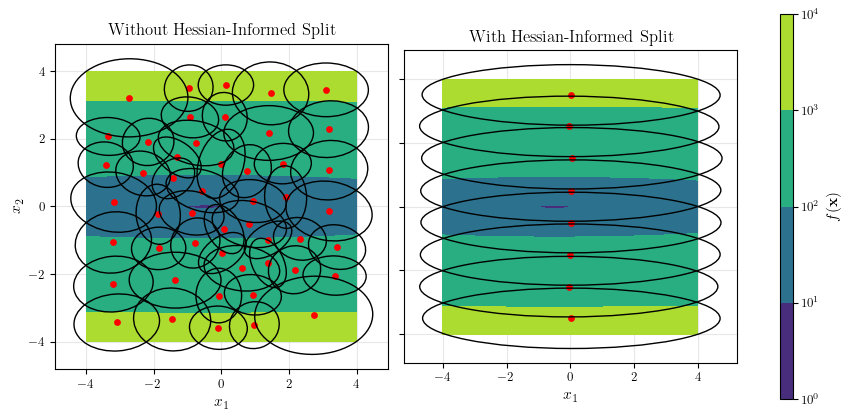

In [ ]:
SEED = 0
np.random.seed(SEED)

DIM = 2
TOL = 0.05
N_TRAIN = get_N_TRAIN(DIM)
N_INIT_CLUSTERS = 1
N_MIN_PER_CLUSTER = 1000

DOMAIN = [-4, 4]
X_train = np.random.uniform(DOMAIN[0], DOMAIN[1], size=(N_TRAIN, DIM))

f_fn = aniso_quadratic
g_fn = aniso_quadratic_grad

# f_fn = quadratic
# g_fn = quadratic_grad

res_without_hess = adaptive_clustering(
    X=X_train,
    f_fn=f_fn,
    g_fn=g_fn,
    TOL=TOL,
    NUM_INITIAL_CLUSTERS=N_INIT_CLUSTERS,
    MIN_PTS_PER_CLUSTER=N_MIN_PER_CLUSTER,
    USE_HESSIAN_INFORMED_SPLIT=False,
    SEED=SEED,
)
print(f"Number of clusters without Hessian: {res_without_hess['centroids'].shape[0]}")
res_with_hess = adaptive_clustering(
    X=X_train,
    f_fn=f_fn,
    g_fn=g_fn,
    TOL=TOL,
    NUM_INITIAL_CLUSTERS=N_INIT_CLUSTERS,
    MIN_PTS_PER_CLUSTER=N_MIN_PER_CLUSTER,
    USE_HESSIAN_INFORMED_SPLIT=True,
    SEED=SEED,
)
print(f"Number of clusters with Hessian: {res_with_hess['centroids'].shape[0]}")

# Plot controuf of f with centroids
x = np.linspace(DOMAIN[0], DOMAIN[1], 400)
y = np.linspace(DOMAIN[0], DOMAIN[1], 400)
X, Y = np.meshgrid(x, y)
Z = f_fn(np.vstack([X.ravel(), Y.ravel()]).T).reshape(X.shape)


fig, axs = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"wspace": 0.05})

contour = None
for i in range(2):
    # Plot the background contour
    contour = axs[i].contourf(X, Y, Z, levels=50, cmap="viridis", norm=LogNorm())

    axs[i].set_xlabel(r"$x_1$")

    # Only keep the y-label on the first (left) subplot to save space
    if i == 0:
        axs[i].set_ylabel(r"$x_2$")
    else:
        axs[i].set_yticklabels([])

    axs[i].set_aspect("equal", adjustable="box")

cases = [
    (0, res_without_hess, "Without Hessian-Informed Split"),
    (1, res_with_hess, "With Hessian-Informed Split"),
]

for ax_idx, res, title in cases:
    ax = axs[ax_idx]
    ax.scatter(
        res["centroids"][:, 0],
        res["centroids"][:, 1],
        color="red",
        marker="o",
        s=15,
    )

    for i in range(res["centroids"].shape[0]):
        mu = res["centroids"][i]
        mu_x, mu_y = mu

        Q = res["Q"][i]
        eigvals, eigvecs = np.linalg.eigh(Q)
        order = np.argsort(eigvals)
        eigvals = eigvals[order]
        eigvecs = eigvecs[:, order]

        axes_lengths = 2 / np.sqrt(eigvals + 1e-12)
        width, height = axes_lengths
        angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))

        ellipse = Ellipse(
            xy=mu,
            width=width,
            height=height,
            angle=angle,
            edgecolor="black",
            facecolor="none",
            linewidth=1,
        )
        ax.add_patch(ellipse)

    ax.set_title(title)

    # Set x and y limits to 2.2
    # ax.set_xlim(DOMAIN[0] * 1.1, DOMAIN[1] * 1.1)
    # ax.set_ylim(DOMAIN[0] * 1.1, DOMAIN[1] * 1.1)

# 2. Add a single colorbar that shares space with both subplots
# 'aspect=30' makes it a bit thinner to fit the wider figure
fig.colorbar(contour, ax=axs.tolist(), label=r"$f(\mathbf{x})$", aspect=30)

plt.savefig("hessian_vs_no_hessian_clusters_iso_quad.pdf", bbox_inches="tight", dpi=300)

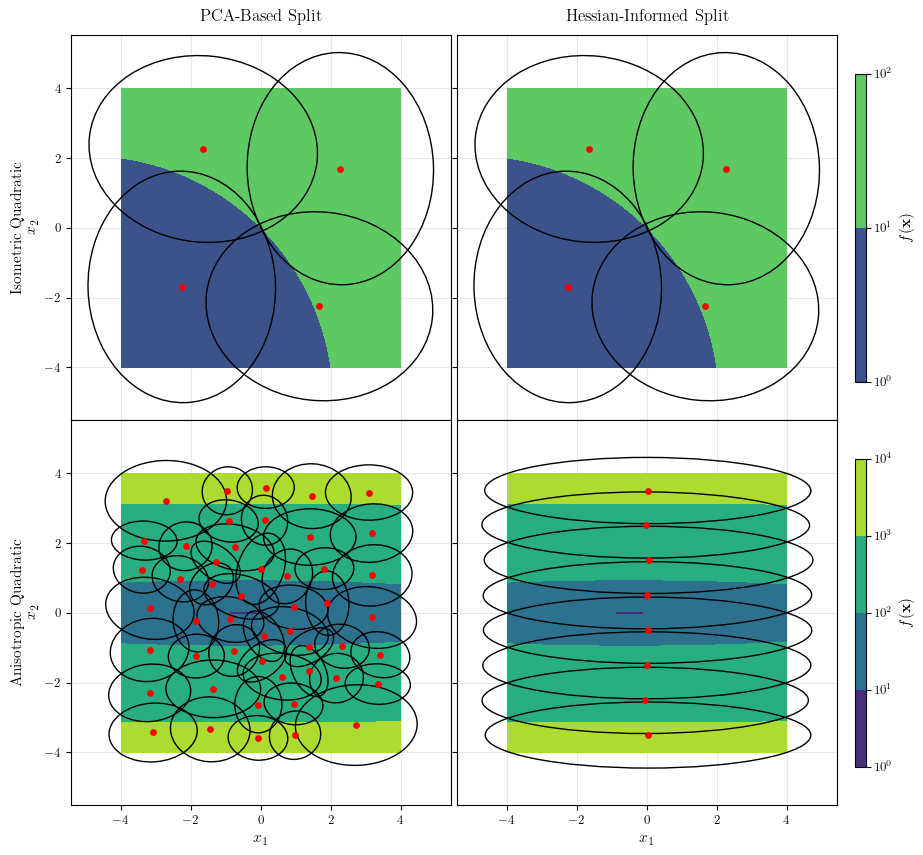

In [114]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from matplotlib.patches import Ellipse

# --- Configuration ---
SEED = 0
np.random.seed(SEED)
DIM = 2
TOL = 0.05
N_TRAIN = get_N_TRAIN(DIM)
N_INIT_CLUSTERS = 1
N_MIN_PER_CLUSTER = 1000
DOMAIN = [-4, 4]

# Function definitions mapping
# Row 0: Isometric Quadratic, Row 1: Anisotropic Quadratic
funcs = [
    {"name": "Isometric Quadratic", "f": quadratic, "g": quadratic_grad},
    {"name": "Anisotropic Quadratic", "f": aniso_quadratic, "g": aniso_quadratic_grad},
]

# --- Data Generation & Plotting ---
fig, axs = plt.subplots(
    2,
    2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
    gridspec_kw={"wspace": 0, "hspace": 0},
)

x = np.linspace(DOMAIN[0], DOMAIN[1], 400)
y = np.linspace(DOMAIN[0], DOMAIN[1], 400)
X, Y = np.meshgrid(x, y)

for row_idx, func_info in enumerate(funcs):
    f_fn = func_info["f"]
    g_fn = func_info["g"]

    # Calculate global Z for this row for consistent contouring
    Z = f_fn(np.vstack([X.ravel(), Y.ravel()]).T).reshape(X.shape)

    # Run clustering for both cases in this row
    res_no_hess = adaptive_clustering(
        X_train,
        f_fn=f_fn,
        g_fn=g_fn,
        TOL=TOL,
        NUM_INITIAL_CLUSTERS=N_INIT_CLUSTERS,
        MIN_PTS_PER_CLUSTER=N_MIN_PER_CLUSTER,
        USE_HESSIAN_INFORMED_SPLIT=False,
        SEED=SEED,
    )
    res_with_hess = adaptive_clustering(
        X_train,
        f_fn=f_fn,
        g_fn=g_fn,
        TOL=TOL,
        NUM_INITIAL_CLUSTERS=N_INIT_CLUSTERS,
        MIN_PTS_PER_CLUSTER=N_MIN_PER_CLUSTER,
        USE_HESSIAN_INFORMED_SPLIT=True,
        SEED=SEED,
    )

    cases = [
        (0, res_no_hess, "PCA-Based Split"),
        (1, res_with_hess, "Hessian-Informed Split"),
    ]

    contour = None
    for col_idx, res, title in cases:
        ax = axs[row_idx, col_idx]

        # Plot background contour
        contour = ax.contourf(X, Y, Z, levels=50, cmap="viridis", norm=LogNorm())

        # Plot Centroids
        ax.scatter(
            res["centroids"][:, 0],
            res["centroids"][:, 1],
            color="red",
            marker="o",
            s=15,
            zorder=3,
        )

        # Plot Trust Region Ellipses
        for i in range(res["centroids"].shape[0]):
            mu = res["centroids"][i]
            Q = res["Q"][i]
            eigvals, eigvecs = np.linalg.eigh(Q)
            order = np.argsort(eigvals)
            eigvals = eigvals[order]
            eigvecs = eigvecs[:, order]

            axes_lengths = 2 / np.sqrt(eigvals + 1e-12)
            angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))

            ellipse = Ellipse(
                xy=mu,
                width=axes_lengths[0],
                height=axes_lengths[1],
                angle=angle,
                edgecolor="black",
                facecolor="none",
                linewidth=1,
                zorder=2,
            )
            ax.add_patch(ellipse)

        # Labels and Formatting
        ax.set_aspect("equal", adjustable="box")

        # Only show titles on the top row
        if row_idx == 0:
            ax.set_title(title, fontsize=12, pad=10)

        # Row Labels (Isometric / Anisotropic)
        if col_idx == 0:
            ax.set_ylabel(f"{func_info['name']}\n$x_2$", fontsize=11)

        # X-labels only on bottom row
        if row_idx == 1:
            ax.set_xlabel(r"$x_1$", fontsize=11)

    # Add one colorbar per row
    # aspect=30 makes it thinner; shrink adjusts height
    cbar = fig.colorbar(
        contour,
        ax=axs[row_idx, :],
        location="right",
        label=r"$f(\mathbf{x})$",
        aspect=30,
        shrink=0.8,
        pad=0.02,
    )

plt.savefig("hessian_comparison_4panel.png", bbox_inches="tight", dpi=300)
plt.show()